<a href="https://colab.research.google.com/github/Pavani-Choppa/Fashion_Mist/blob/main/Fashion_Mist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.metrics import classification_report, confusion_matrix

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [4]:
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [5]:
class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]
print(class_names)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


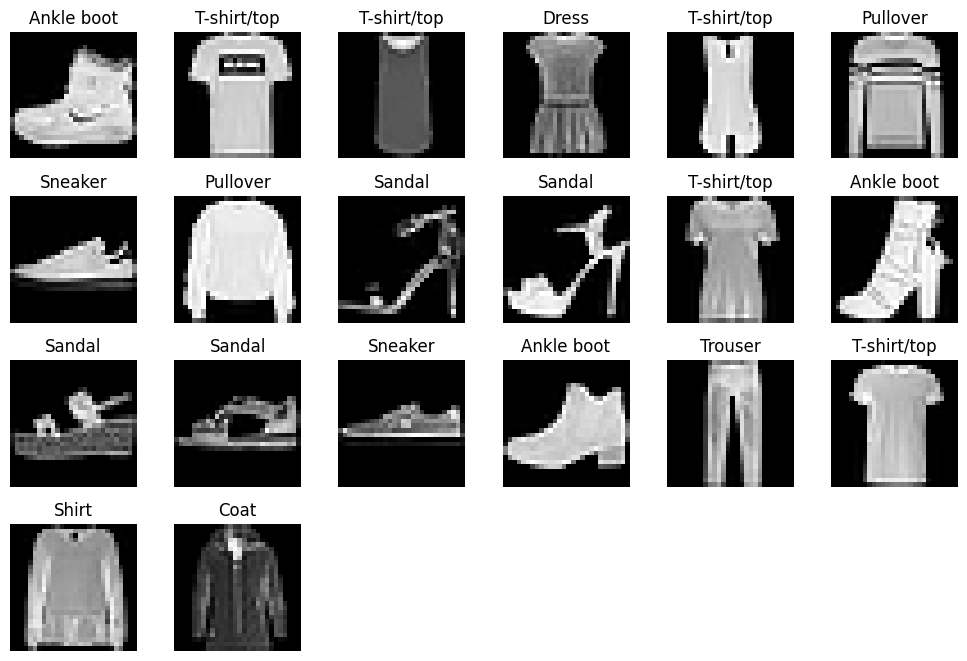

In [10]:
plt.figure(figsize=(10, 10))

for i in range(20):
   plt.subplot(6, 6, i + 1 )
   plt.imshow(X_train[i], cmap="gray")
   plt.title(class_names[y_train[i]])
   plt.axis("off")
   plt.tight_layout()

In [6]:
print("Minimum pixel value :",X_train.min())
print("Maximum pixel value :",X_train.max())

Minimum pixel value : 0
Maximum pixel value : 255


Normalize the Images


In [11]:

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [13]:
X_train = X_train [..., np.newaxis]
X_test = X_test[..., np.newaxis]
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1, 1)
Testing shape: (10000, 28, 28, 1, 1)


Built CNN


Input → Conv2D → MaxPooling → Conv2D → MaxPooling → Flatten Dense → Dropout →
Output


In [14]:
model = models. Sequential ([
  layers.Input (shape=(28, 28, 1)),
  layers.Conv2D(
    32,
    (3, 3),
    activation="relu"
  ),

  layers.MaxPooling2D(
     pool_size=(2, 2)
  ),

  layers.Conv2D(
    64,
    (3, 3),
    activation="relu"),

  layers.MaxPooling2D(
    pool_size=(2, 2)
  ),


  layers.Flatten(),

  layers.Dense(
    128,
    activation="relu"
  ),
  layers. Dropout (0.5),
  layers.Dense(
    10,
    activation="softmax"
  )
])

In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
  optimizer="adam",
  loss="sparse_categorical_crossentropy",
  metrics=["accuracy"]
)

In [17]:
history = model.fit(
  X_train,
  y_train,
  epochs=10,
  batch_size=64,
  validation_split=0.1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 48s 55ms/step - accuracy: 0.7742 - loss: 0.6261 - val_accuracy: 0.8557 - val_loss: 0.3768
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 55ms/step - accuracy: 0.8567 - loss: 0.4016 - val_accuracy: 0.8787 - val_loss: 0.3213
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 45s 54ms/step - accuracy: 0.8755 - loss: 0.3495 - val_accuracy: 0.8830 - val_loss: 0.2984
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 84s 56ms/step - accuracy: 0.8848 - loss: 0.3176 - val_accuracy: 0.8952 - val_loss: 0.2795
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 53ms/step - accuracy: 0.8946 - loss: 0.2920 - val_accuracy: 0.9062 - val_loss: 0.2522
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 85s 57ms/step - accuracy: 0.8999 - loss: 0.2744 - val_accuracy: 0.9037 - val_loss: 0.2643
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 69s 82ms/step - accuracy: 0.9060 - loss: 0.2557 - val_accuracy: 0.9105 - val_loss: 0.2413
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 74s 72ms/step - accuracy: 0.9133 - loss: 0.2393 - 

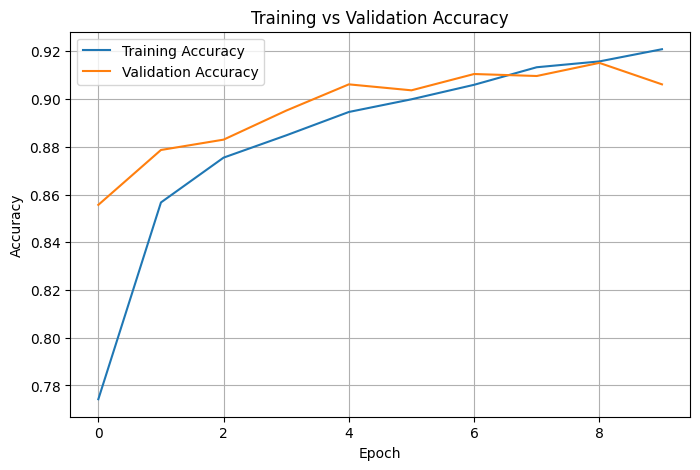

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(
  history.history ["accuracy"],
  label="Training Accuracy"
)
plt.plot(
  history.history["val_accuracy"],
  label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
test_loss, test_accuracy = model.evaluate(
  X_test,
  y_test,
  verbose=1
)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8980 - loss: 0.2746
Test Loss: 0.2746345102787018
Test Accuracy: 0.8980000019073486


In [20]:
y_probability = model.predict(X_test)
y_pred = np.argmax(y_probability, axis=1)
print("Predicted labels:")
print(y_pred[:20])
print("Actual labels:")
print(y_test[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step
Predicted labels:
[9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]
Actual labels:
[9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]


In [21]:
print(
  classification_report(
    y_test,
    y_pred,
    target_names=class_names
  )
)

              precision    recall  f1-score   support

 T-shirt/top       0.88      0.81      0.84      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.90      0.75      0.82      1000
       Dress       0.91      0.91      0.91      1000
        Coat       0.77      0.91      0.84      1000
      Sandal       0.97      0.99      0.98      1000
       Shirt       0.68      0.75      0.71      1000
     Sneaker       0.96      0.96      0.96      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



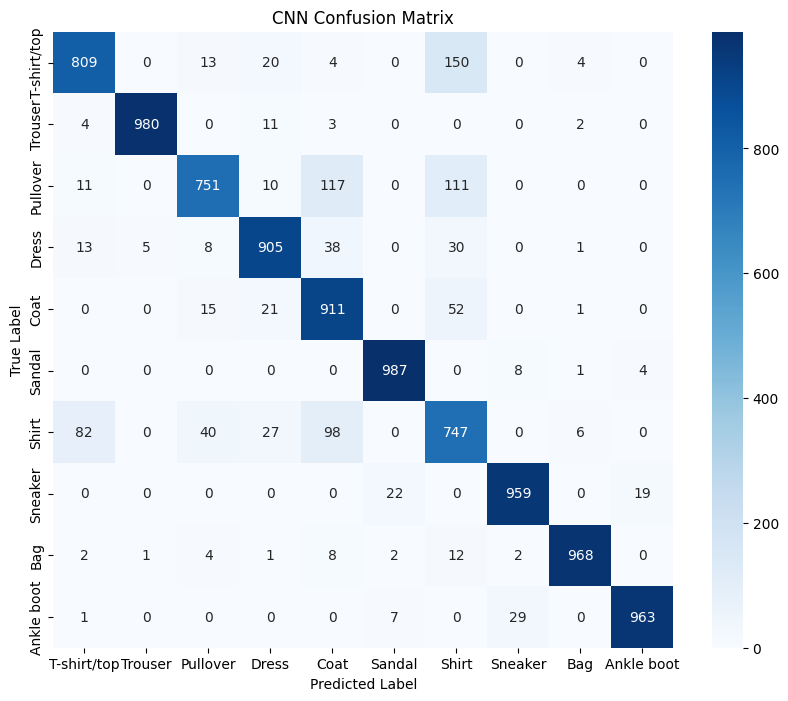

In [22]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(
  cm,
  annot=True,
  fmt="d",
  cmap="Blues",
  xticklabels=class_names,
  yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix")
plt.show()

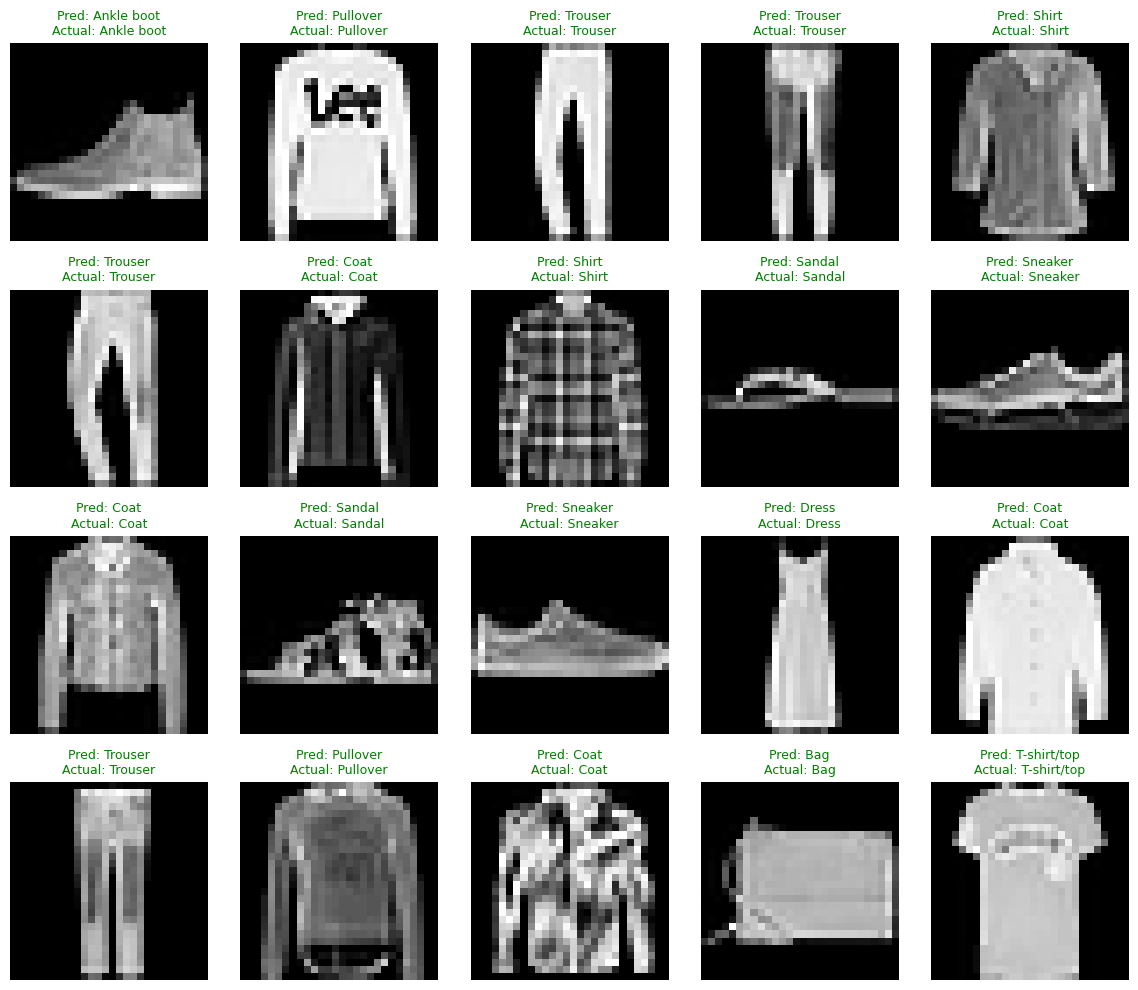

In [24]:
plt.figure(figsize=(12, 10))
for i in range(20):
  plt.subplot(4, 5, i + 1)
  plt.imshow(X_test[i].squeeze(), cmap="gray")
  predicted_class = class_names[y_pred[i]]
  actual_class = class_names[y_test[i]]
  color = "green" if y_pred[i] == y_test[i] else "red"

  plt.title(
    f"Pred: {predicted_class}\nActual: {actual_class}",
    color=color,
    fontsize=9
  )
  plt.axis("off")
  plt.tight_layout()
plt.show()